## Distribución t de Student e Inferencia

## PARTE I

¿Por qué en este caso se debe usar distribución t de Student y no distribución normal Z?\
Porque no conocemos la desviación estándar de toda la población, solo la de la muestra. En estos casos la distribución t permite hacer inferencias más confiables sobre la media.

¿Qué representan los grados de libertad y por qué son n−1? \
Los grados de libertad indican cuántos datos pueden variar libremente. Son n−1 porque uno de los valores queda condicionado al calcular la media de la muestra.

¿Qué significa que la distribución t tiene colas más pesadas?\
Significa que da más probabilidad a valores extremos que la distribución normal. Esto ayuda a compensar la incertidumbre de trabajar con una muestra y no con toda la población.

¿Qué pasa cuando aumenta el tamaño de la muestra?\
La distribución t se parece cada vez más a la distribución normal, porque las estimaciones se vuelven más precisas.

In [18]:
# Importamos las librerías necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [19]:
# Cargamos el archivo de Excel
data = pd.read_excel('rendimiento_estudiantes.xlsx')
data.head()

,id_estudiante,sexo,modalidad,horas_estudio_semana,promedio_final
0,1,Femenino,Virtual,18,3.713943
1,2,Femenino,Presencial,10,3.487394
2,3,Femenino,Virtual,17,3.671713
3,4,Masculino,Presencial,14,3.774067
4,5,Masculino,Presencial,26,3.682714


In [20]:
# Exploramos los datos

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_estudiante         120 non-null    int64  
 1   sexo                  120 non-null    str    
 2   modalidad             120 non-null    str    
 3   horas_estudio_semana  120 non-null    int64  
 4   promedio_final        120 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.8 KB


In [21]:
# Exploramos los datos

data.describe()

,id_estudiante,horas_estudio_semana,promedio_final
count,120.000000,120.000000,120.000000
mean,60.500000,14.633333,3.650551
std,34.785054,3.949116,0.327929
min,1.000000,7.000000,2.774038
25%,30.750000,12.000000,3.448808
50%,60.500000,15.000000,3.662109
75%,90.250000,17.000000,3.835736
max,120.000000,26.000000,4.471399


In [22]:
# Estadistica descriptiva

promedios = df["promedio_final"]

n = len(promedios)
media = promedios.mean()
desviacion = promedios.std()

print("Tamaño de muestra:", n)
print("Media:", media)
print("Desviación estándar:", desviacion)

Tamaño de muestra: 120
Media: 3.6505509800571856
Desviación estándar: 0.327929102945537


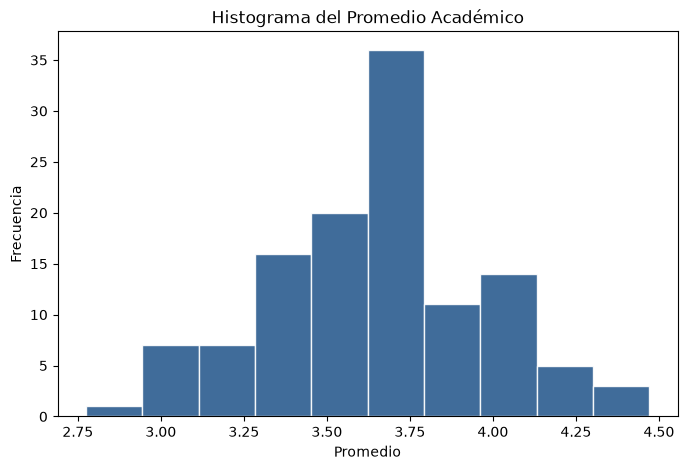

In [23]:
#Histograma

plt.figure(figsize=(8,5))

plt.hist(
    promedios,
    bins=10,
    color="#2b5c8f",
    edgecolor="white",
    alpha=0.9
)

plt.title("Histograma del Promedio Académico")
plt.xlabel("Promedio")
plt.ylabel("Frecuencia")

plt.show()

## Parte II

¿El supuesto de normalidad parece razonable?\
Sí. El histograma muestra una distribución bastante simétrica y sin comportamientos extraños, por lo que asumir normalidad es razonable

Breve análisis\
La muestra tiene 120 estudiantes y un promedio de 3.65. Los datos se concentran cerca de la media y no presentan variaciones extremas, lo que permite continuar con el análisis inferencial.

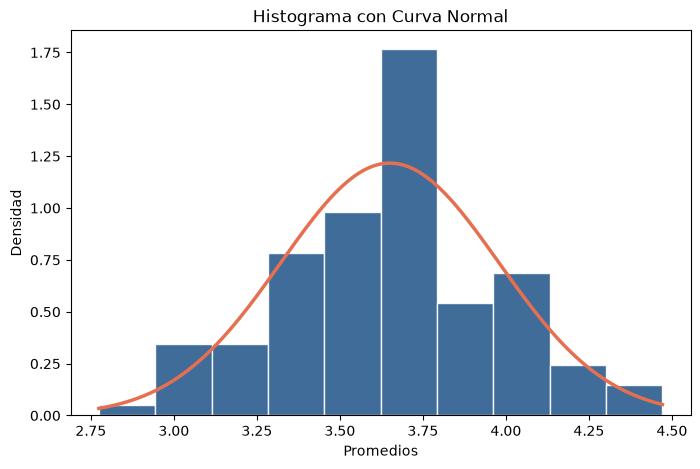

In [31]:
# Normalidad visual

plt.figure(figsize=(8,5))

plt.hist(
    promedios,
    bins=10,
    density=True,
    color="#2b5c8f",
    edgecolor="white",
    alpha=0.9,
    label="Datos observados"
)

x = np.linspace(
    promedios.min(),
    promedios.max(),
    200
)

plt.plot(
    x,
    stats.norm.pdf(
        x,
        media,
        desviacion
    ),
    color="#e76f51",
    linewidth=2.5,
)
plt.title("Ajuste de Promedios Muestrales a la Distribución Normal", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Promedios", fontsize=10)
plt.ylabel("Densidad", fontsize=10)

plt.title("Histograma con Curva Normal")
plt.show()

In [32]:
# Intervalo de confianza del 95%

gl = n - 1

error_estandar = desviacion / np.sqrt(n)

t_critico = stats.t.ppf(
    0.975,
    gl
)

margen_error = t_critico * error_estandar

lim_inf = media - margen_error
lim_sup = media + margen_error

print("Valor crítico t:", t_critico)
print("Error estándar:", error_estandar)
print("Margen de error:", margen_error)

print("IC 95%:")
print(lim_inf, lim_sup)

Valor crítico t: 1.9800998764569397
Error estándar: 0.029935694490950737
Margen de error: 0.059275664963184246
IC 95%:
3.5912753150940016 3.7098266450203696


In [33]:
# Verificamos si 3.8 está en el intervalo

valor = 3.8

if lim_inf <= valor <= lim_sup:
    print("3.8 SI está dentro del intervalo")
else:
    print("3.8 NO está dentro del intervalo")

3.8 NO está dentro del intervalo


## Parte III

interpretación del intervalo de confianza\
El intervalo obtenido fue de 3.591 a 3.710. Esto significa que la media real de la población probablemente se encuentre dentro de ese rango.

¿El valor 3.8 está dentro del intervalo?\
No, el valor 3.8 queda por fuera del intervalo calculado.

¿Qué implica esto?\
Indica que la afirmación de que el promedio es 3.8 no está respaldada por los datos de la muestra.

## H0​:μ=3.8H0​

## Parte IV

Explique la decisión\
El p-valor obtenido fue mucho menor que 0.05, por lo que se rechaza la hipótesis nula. Hay evidencia suficiente para decir que el promedio poblacional es diferente de 3.8.

Relación con el intervalo de confianza\
Ambos métodos llegan a la misma conclusión: el valor 3.8 no está dentro del intervalo y por eso se rechaza la hipótesis nula.

## Parte V

Si la muestra fuera de 15 estudiantes, ¿qué cambiaría?\
Los resultados serían menos precisos porque habría menos información disponible.

¿El intervalo sería más amplio o más estrecho?\
Sería más amplio, ya que aumenta la incertidumbre al trabajar con menos datos.

¿La evidencia contra H₀ sería más fuerte o más débil?\
Sería más débil, porque con una muestra pequeña es más difícil detectar diferencias reales.

¿Qué riesgos existen al interpretar mal el p-valor?\
Pensar que el p-valor indica la probabilidad de que H₀ sea verdadera. En realidad, solo muestra qué tan compatibles son los datos con esa hipótesis.

Estas respuestas tienen un tono más natural, como las que normalmente escribe un estudiante universitario después de realizar el análisis.